# Integração e Tratamento de Dados

## Preparação do ambiente: 

Ao iniciar um processo de obtenção e tratamento de dados, é sempre importante manter um padrão de trabalho: quais bibliotecas são carregadas, quais funções são tornadas disponíveis, ajuste dos parâmetros para resultados dentro da norma da empresa etc.

In [242]:
rm(list=ls())

In [215]:
# biblioteca de definição de representações
library(repr)
# função para definir dimensão da célula de gráfico no Jupyter:
dimgraf <- function (x=11, y=7) { 
    options(repr.plot.width=x,repr.plot.height=y) 
}

## Extração

 Obtenção dos dados

In [244]:
sal <- read.csv("SalarySurvey2021.csv", header=TRUE, sep=",")

Resumo:

In [245]:
summary(sal)

  Timestamp         How.old.are.you.   What.industry.do.you.work.in.
 Length:28075       Length:28075       Length:28075                 
 Class :character   Class :character   Class :character             
 Mode  :character   Mode  :character   Mode  :character             
                                                                    
                                                                    
                                                                    
                                                                    
  Job.title        
 Length:28075      
 Class :character  
 Mode  :character  
                   
                   
                   
                   
 If.your.job.title.needs.additional.context..please.clarify.here.
 Length:28075                                                    
 Class :character                                                
 Mode  :character                                                
                        

O arquivo de dados `CSV` contém, como nome das variáveis, o texto da questão. É necessário então nomear as variáveis segundo seu significado.

In [246]:
str(sal)

'data.frame':	28075 obs. of  18 variables:
 $ Timestamp                                                                                                                                                                                                                           : chr  "4/27/2021 11:02:10" "4/27/2021 11:02:22" "4/27/2021 11:02:38" "4/27/2021 11:02:41" ...
 $ How.old.are.you.                                                                                                                                                                                                                    : chr  "25-34" "25-34" "25-34" "25-34" ...
 $ What.industry.do.you.work.in.                                                                                                                                                                                                       : chr  "Education (Higher Education)" "Computing or Tech" "Accounting, Banking & Finance" "Nonprofits" ...
 $ Job.title       

* "timestamp" → `tempo`;
* "How.old.are.you" → `idade`
* "What.industry.do.you.work.in" → ramo de trabalho, `industria`;
* "Job.title" → nome do `cargo`;
* "If.your.job.title.needs.additional.context..please.clarify.here" → explicações adicionais do cargo (`cargo_adic`);
* "What is your annual salary. You'll indicate the currency in a later question. If you are part time or hourly please enter an annualized equivalent. what you would earn if you worked the job 40 hours a week 52 weeks a year → `salario`;
* "How much additional monetary compensation do you get  if any  for example  bonuses or overtime in an average year   Please only include monetary compensation here  not the value of benefits" → bônus ou recebimento adicional (`bonus`);
* "Please.indicate.the.currency" → `moeda`;
* "If..Other...please.indicate.the.currency.here" → se outra moeda (`moeda_outra`);
* "If.your.income.needs.additional.context..please.provide.it.here." → se salário possui contexto adicional (`salario_contexto`);
* "What.country.do.you.work.in" → `pais`;
* "If.you.re.in.the.U.S...what.state.do.you.work.in" → se nos EUA, qual estado (`estado_eua`);
* "What.city.do.you.work.in" → `cidade`;
* "How.many.years.of.professional.work.experience.do.you.have.overall" → `anos_exp_total`;
* "How.many.years.of.professional.work.experience.do.you.have.in.your.field" → `anos_exp_area`;
* "What.is.your.highest.level.of.education.completed" → nível de educação (`educacao`);
* "What.is.your.gender" → `sexo`;
* "What.is.your.race...Choose.all.that.apply" → "raça" (`etnia`).

In [247]:
names(sal) <- c("tempo", "idade", "industria", "cargo", "cargo_adic", "salario", "bonus",
                "moeda", "moeda_outra","salario_contexto", "pais", "estado_eua", "cidade",
                "anos_exp_total", "anos_exp_area", "educacao", "sexo", "etnia")

In [248]:
summary(sal)

    tempo              idade            industria            cargo          
 Length:28075       Length:28075       Length:28075       Length:28075      
 Class :character   Class :character   Class :character   Class :character  
 Mode  :character   Mode  :character   Mode  :character   Mode  :character  
                                                                            
                                                                            
                                                                            
                                                                            
  cargo_adic          salario              bonus              moeda          
 Length:28075       Length:28075       Min.   :        0   Length:28075      
 Class :character   Class :character   1st Qu.:        0   Class :character  
 Mode  :character   Mode  :character   Median :     2000   Mode  :character  
                                       Mean   :    18159                

Qual o tipo do conteúdo das variáveis?

In [249]:
print(head(sal))

               tempo idade                     industria
1 4/27/2021 11:02:10 25-34  Education (Higher Education)
2 4/27/2021 11:02:22 25-34             Computing or Tech
3 4/27/2021 11:02:38 25-34 Accounting, Banking & Finance
4 4/27/2021 11:02:41 25-34                    Nonprofits
5 4/27/2021 11:02:42 25-34 Accounting, Banking & Finance
6 4/27/2021 11:02:46 25-34  Education (Higher Education)
                                     cargo cargo_adic salario bonus moeda
1       Research and Instruction Librarian             55,000     0   USD
2 Change & Internal Communications Manager             54,600  4000   GBP
3                     Marketing Specialist             34,000    NA   USD
4                          Program Manager             62,000  3000   USD
5                       Accounting Manager             60,000  7000   USD
6           Scholarly Publishing Librarian             62,000    NA   USD
  moeda_outra salario_contexto           pais     estado_eua      cidade
1         

In [250]:
print(tail(sal))

                   tempo idade                     industria
28070 9/10/2024 23:58:45 35-44             Computing or Tech
28071 9/12/2024 20:59:43 25-34  Education (Higher Education)
28072 9/13/2024 16:59:35 25-34 Accounting, Banking & Finance
28073 9/17/2024 11:10:17 35-44 Education (Primary/Secondary)
28074 9/17/2024 11:43:33 18-24             Computing or Tech
28075 9/17/2024 12:03:31 18-24             Computing or Tech
                         cargo cargo_adic salario bonus moeda moeda_outra
28070 Business Systems Analyst              90000  9000   USD            
28071       Community Director              37741    NA   USD            
28072         Staff Accountant              62500    NA   USD            
28073         HOMEROOM TEACHER              70000 15000   USD            
28074                  Student                500    NA   USD            
28075                  Student               1000   200   USD            
                           salario_contexto          pa

In [251]:
save(sal, file="SalarySurvey2021_01_leitura.RData")

## Transformação

O próximo passo é a avaliação da estrutura das variáveis e sua adequação para os procedimentos de análise.

In [217]:
rm(list=ls()) # Limpando variáveis intermediárias da memória

In [218]:
load("SalarySurvey2021_01_leitura.RData")
dimgraf <- function (x=11, y=7) { options(repr.plot.width=x,repr.plot.height=y) }
ls()

[1] "dimgraf" "sal"

### Limpeza e preparação das variáveis

A maior parte das variáveis é categórica (_fatores_). O marco temporal pode ser convertido via POSIX.

#### `tempo`

In [219]:
head(sal$tempo)

[1] "4/27/2021 11:02:10" "4/27/2021 11:02:22" "4/27/2021 11:02:38"
[4] "4/27/2021 11:02:41" "4/27/2021 11:02:42" "4/27/2021 11:02:46"

É um registro tipo POSIX do tempo. Pode ser convertido.

In [220]:
sal$tempo <- as.POSIXct(sal$tempo, format='%m/%d/%Y %H:%M:%S')

In [221]:
str(sal$tempo)

 POSIXct[1:28075], format: "2021-04-27 11:02:10" "2021-04-27 11:02:22" "2021-04-27 11:02:38" ...


In [222]:
summary(sal$tempo)

                      Min.                    1st Qu. 
"2021-04-27 11:02:10.0000" "2021-04-27 14:21:35.5000" 
                    Median                       Mean 
"2021-04-28 13:57:11.0000" "2021-05-15 10:18:53.2120" 
                   3rd Qu.                       Max. 
"2021-04-29 20:31:53.5000" "2024-09-17 12:03:31.0000" 

#### `idade`

In [223]:
head(sal$idade)
tail(sal$idade)

[1] "25-34" "25-34" "25-34" "25-34" "25-34" "25-34"

[1] "35-44" "25-34" "25-34" "35-44" "18-24" "18-24"

São faixas etárias. Quais são?

In [224]:
unique(sal$idade)

[1] "25-34"      "45-54"      "35-44"      "18-24"      "65 or over"
[6] "55-64"      "under 18"

**Fator em R:**

<img src="img/factor.png">

In [225]:
sal$idade[sal$idade == 'under 18'] <- '-18'

In [226]:
sal$idade[sal$idade == '65 or over'] <- '65+'

In [227]:
idade_ordem <- c("-18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+")

In [228]:
sal$idade <- factor(sal$idade, ordered=TRUE, levels=idade_ordem, labels=idade_ordem)

In [229]:
print(summary(sal$idade))

  -18 18-24 25-34 35-44 45-54 55-64   65+ 
   14  1224 12660  9902  3189   992    94 


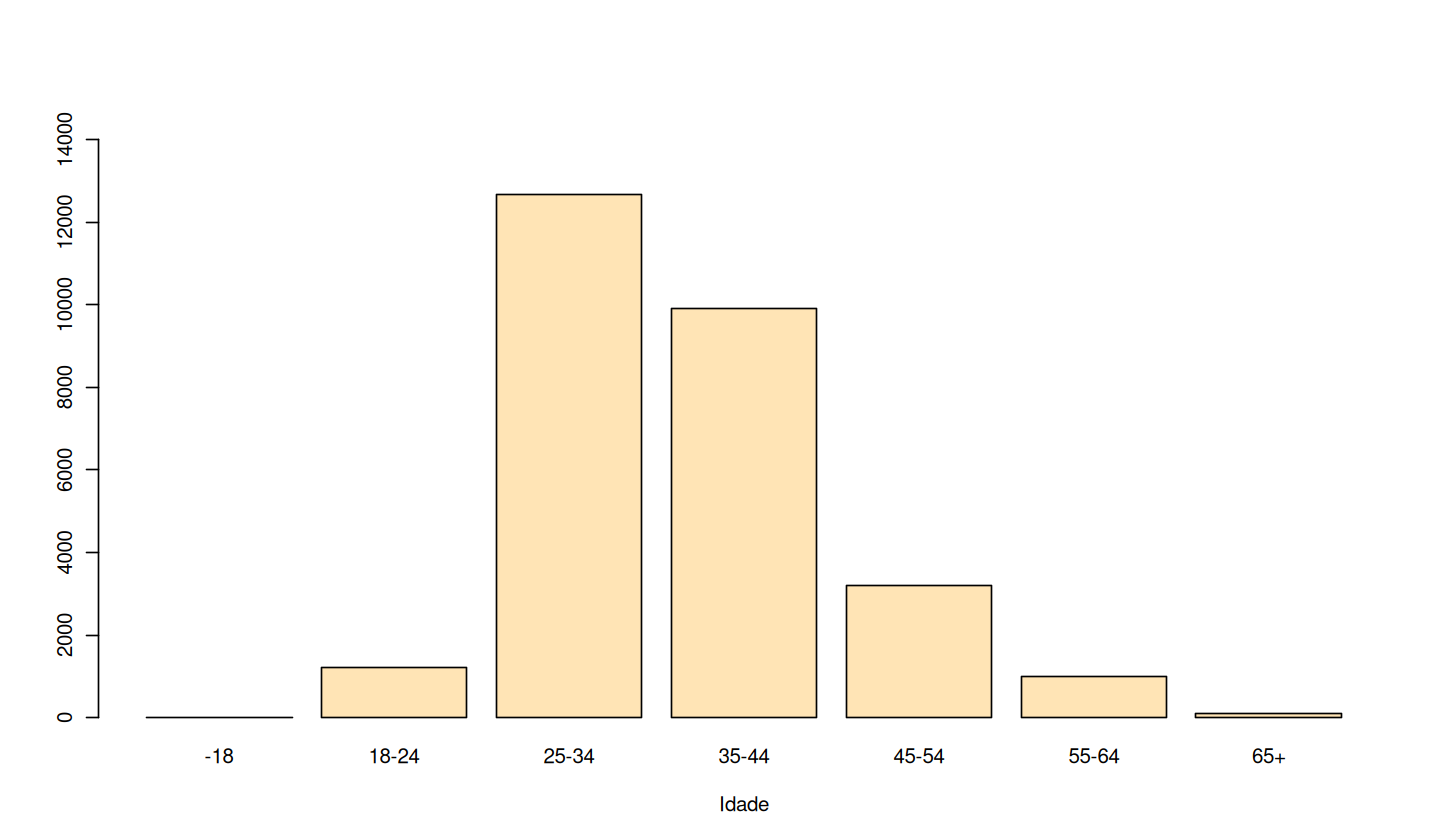

In [230]:
dimgraf(x=12,y=7)
barplot(table(sal$idade),ylim=c(0,15000), col="moccasin", xlab="Idade")

#### `industria`

In [231]:
ind <- tolower(sal$industria)

In [232]:
head(ind)
tail(ind)

[1] "education (higher education)"  "computing or tech"            
[3] "accounting, banking & finance" "nonprofits"                   
[5] "accounting, banking & finance" "education (higher education)"

[1] "computing or tech"             "education (higher education)" 
[3] "accounting, banking & finance" "education (primary/secondary)"
[5] "computing or tech"             "computing or tech"

In [233]:
print(unique(ind)[1:100])

  [1] "education (higher education)"                                                 
  [2] "computing or tech"                                                            
  [3] "accounting, banking & finance"                                                
  [4] "nonprofits"                                                                   
  [5] "publishing"                                                                   
  [6] "education (primary/secondary)"                                                
  [7] "law"                                                                          
  [8] "health care"                                                                  
  [9] "utilities & telecommunications"                                               
 [10] "business or consulting"                                                       
 [11] "art & design"                                                                 
 [12] "government and public administration"          

In [234]:
ind <- factor(ind)

In [235]:
print(summary(ind))

                   computing or tech         education (higher education) 
                                4704                                 2466 
                          nonprofits                          health care 
                                2419                                 1896 
government and public administration        accounting, banking & finance 
                                1890                                 1811 
        engineering or manufacturing          marketing, advertising & pr 
                                1695                                 1134 
                                 law               business or consulting 
                                1097                                  852 
       education (primary/secondary)                      media & digital 
                                 836                                  774 
                           insurance                               retail 
                         

Há muitas categorias. Talvez seja interessante avaliar apenas as mais frequentes. Vamos considerar as categorias que commpreendam 80% das observações:

In [236]:
nrow(sal) * 0.8

[1] 22460

Vamos manter as categorias até 22460 e unificar em `outras` as demais, mesmo sob o custo de alguma categoria estar duplicada com nome diferente.

In [237]:
4704 + 2466 + 2419 + 1896 + 1890 + 1811 + 1695 + 1134 + 1097 + 852 + 
836 + 774 + 531 + 505 + 460
# 460 foi mantido por estar perto de 505 e longe da próxima 387

[1] 23070

As categorias que ficaram então são:
``` raw
computing or tech     4704
education (higher education)     2466
nonprofits     2419
health care    1896
government and public administration    1890
accounting, banking & finance    1811
engineering or manufacturing    1695
marketing, advertising & pr    1134
law    1097
business or consulting    852
education (primary/secondary)    836
media & digital    774
insurance    531
retail    505
```

TODO [fazer análise fina das categorias, unificando nomes similares]  
Exemplo:

In [238]:
ind <- tolower(sal$industria)
ind[ind != 'computing or tech' &
    ind != 'education (higher education)' &
    ind != 'nonprofits' &
    ind != 'health care' &
    ind != 'government and public administration' &
    ind != 'accounting, banking & finance' &
    ind != 'engineering or manufacturing' &
    ind != 'marketing, advertising & pr' &
    ind != 'law' &
    ind != 'business or consulting' &
    ind != 'education (primary/secondary)' &
    ind != 'media & digital' &
    ind != 'insurance' &
    ind != 'retail'] <- 'other' 
ind <- factor(ind)

In [239]:
print(summary(ind))

       accounting, banking & finance               business or consulting 
                                1811                                  852 
                   computing or tech         education (higher education) 
                                4704                                 2466 
       education (primary/secondary)         engineering or manufacturing 
                                 836                                 1695 
government and public administration                          health care 
                                1890                                 1896 
                           insurance                                  law 
                                 531                                 1097 
         marketing, advertising & pr                      media & digital 
                                1134                                  774 
                          nonprofits                                other 
                         

In [240]:
print(head(sal$industria))
print(head(ind))

[1] "Education (Higher Education)"  "Computing or Tech"            
[3] "Accounting, Banking & Finance" "Nonprofits"                   
[5] "Accounting, Banking & Finance" "Education (Higher Education)" 
[1] education (higher education)  computing or tech            
[3] accounting, banking & finance nonprofits                   
[5] accounting, banking & finance education (higher education) 
15 Levels: accounting, banking & finance ... retail


In [241]:
sal$industria <- ind
summary(sal)

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
  cargo_adic          salario              bonus              moeda          
 Length:28075       Length

#### `cargo`

In [242]:
cargo <- sal$cargo

In [243]:
head(cargo)

[1] "Research and Instruction Librarian"      
[2] "Change & Internal Communications Manager"
[3] "Marketing Specialist"                    
[4] "Program Manager"                         
[5] "Accounting Manager"                      
[6] "Scholarly Publishing Librarian"

In [244]:
print(summary(factor(cargo)))

          Software Engineer             Project Manager 
                        286                         230 
                   Director    Senior Software Engineer 
                        198                         196 
            Program Manager                     Teacher 
                        152                         151 
                  Librarian                     Manager 
                        150                         145 
        Executive Assistant             Product Manager 
                        136                         125 
   Administrative Assistant                Data Analyst 
                        103                          99 
                   Attorney                   Associate 
                         97                          94 
          Marketing Manager                     Analyst 
                         91                          89 
             Office Manager          Software Developer 
                         89    

> Os cargos de uma indústria são comuns?

In [245]:
head(sal$cargo[sal$industria=='computing or tech'],20)

[1] "Change & Internal Communications Manager"
 [2] "Systems Analyst"                         
 [3] "Principal Software Engineer"             
 [4] "Intelligence Analyst"                    
 [5] "Mobile developer"                        
 [6] "Product Design Director"                 
 [7] "Managed Services Sales Coordinator"      
 [8] "Technical specialist"                    
 [9] "Tech Writer"                             
[10] "Senior Business Analyst"                 
[11] "Director of Engineering"                 
[12] "senior web application developer"        
[13] "Chief Engineer"                          
[14] "Senior Financial Analyst"                
[15] "Software engineer"                       
[16] "Product Manager"                         
[17] "Service Designer"                        
[18] "Software Development Manager"            
[19] "technical support specialist"            
[20] "Systems Analyst"

> Não. Aparentemente a indústria tem respondentes de todo tipo de cargo.

Seria interessante manter a variável, mas dificilmente será útil na análise.

#### `cargo_adic`

In [246]:
head(sal$cargo_adic,20)
tail(sal$cargo_adic,20)

[1] ""                             ""                            
 [3] ""                             ""                            
 [5] ""                             ""                            
 [7] ""                             "High school, FT"             
 [9] "Data developer/ETL Developer" ""                            
[11] ""                             ""                            
[13] ""                             "non-profit law firm"         
[15] ""                             ""                            
[17] ""                             ""                            
[19] ""                             ""

[1] ""       ""       ""       ""       ""       ""       ""       ""      
 [9] ""       ""       "Claims" ""       ""       ""       ""       ""      
[17] ""       ""       ""       ""

In [247]:
sal$cargo_adic <- NULL

In [248]:
print(summary(sal))

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
   salario              bonus              moeda           moeda_outra       
 Length:28075       Min.  

#### `salario`

In [249]:
head(sal$salario)
tail(sal$salario)
max(nchar(sal$salario))

[1] "55,000" "54,600" "34,000" "62,000" "60,000" "62,000"

[1] "90000" "37741" "62500" "70000" "500"   "1000"

[1] 11

In [250]:
sal$salario[nchar(sal$salario) > 7]

[1] "1,080,000"   "1,150,000"   "3,000,000"   "1,400,000"   "102,000,000"
 [6] "1,150,000"   "1,100,000"   "2,800,000"   "1,100,000"   "1,200,000"  
[11] "1,900,000"   "1,650,000"   "1,334,782"   "4,600,000"   "8,100,000"  
[16] "6,000,000"   "4,800,000"   "6,000,000"   "1,150,000"   "11,500,000" 
[21] "1,100,000"   "2,100,000"   "1,200,000"   "27,000,000"  "5,600,000"  
[26] "3,225,000"   "870,000,000" "1,324,000"   "2,500,000"   "6,000,000"  
[31] "2,300,000"   "2,111,538"   "3,600,000"   "1,100,000"   "3,600,000"  
[36] "1,300,000"   "1,260,000"   "8,800,000"   "38,000,000"  "4,000,000"  
[41] "1,360,000"   "1,300,000"   "180,000,000" "4,600,000"   "4,160,000"  
[46] "1,050,000"   "36000000"    "43800000"    "20800000"    "120000000"  
[51] "10000000"    "6000070000"

Inicialmente, seria necessário retirar as `,`:

In [251]:
sal$salario <- gsub(',', '', sal$salario)
sal$salario[nchar(sal$salario) > 7]

[1] "102000000"  "11500000"   "27000000"   "870000000"  "38000000"  
 [6] "180000000"  "36000000"   "43800000"   "20800000"   "120000000" 
[11] "10000000"   "6000070000"

Aparentemente `6000070000` deve ter sido entrado 60000-70000. Substituindo por 65000.

In [252]:
sal$salario[sal$salario=='6000070000'] <- '65000'
sal$salario[nchar(sal$salario) > 7]

[1] "102000000" "11500000"  "27000000"  "870000000" "38000000"  "180000000"
 [7] "36000000"  "43800000"  "20800000"  "120000000" "10000000"

In [253]:
sal$salario <- as.numeric(sal$salario)

In [254]:
summary(sal$salario)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
        0     54000     75000    147570    109884 870000000 

Como estariam distribuídos os salários?

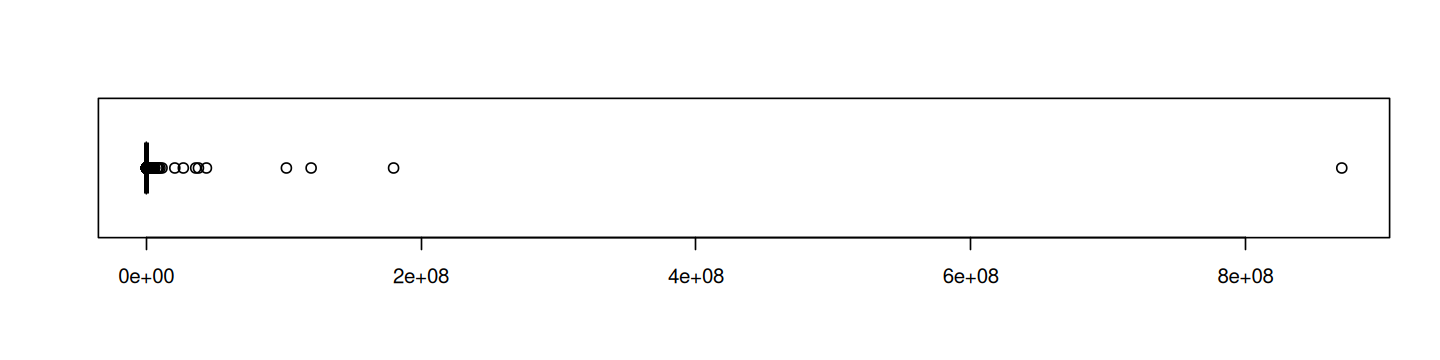

In [255]:
dimgraf(12,3)
boxplot(sal$salario, horizontal=TRUE, col="moccasin")

Aparentemente um valor extremo distorceu o boxplot:

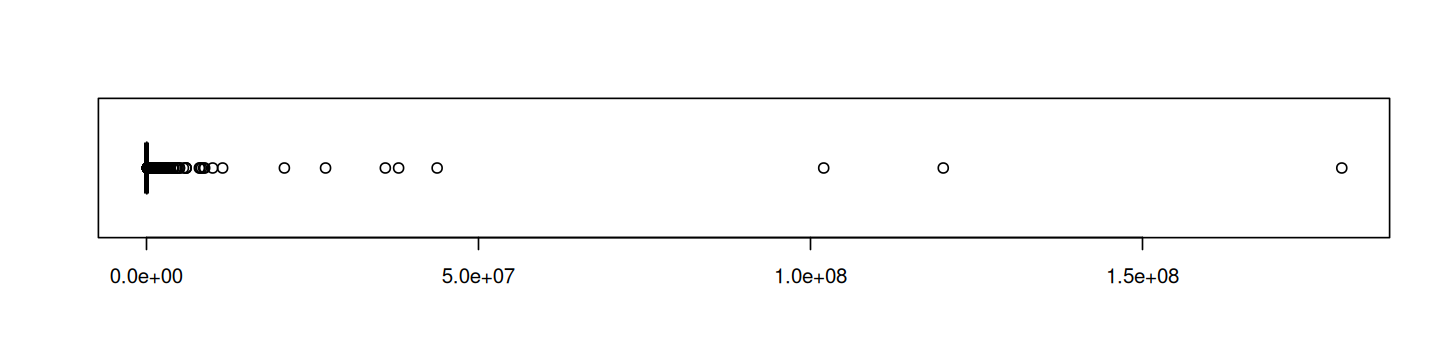

In [256]:
boxplot(sal$salario[sal$salario < 2e8], horizontal=TRUE, col="moccasin")

Ainda há valores extremos, provavelmente provenientes das outras moedas. Como curiosidade, vamos observar até 3º quartil:

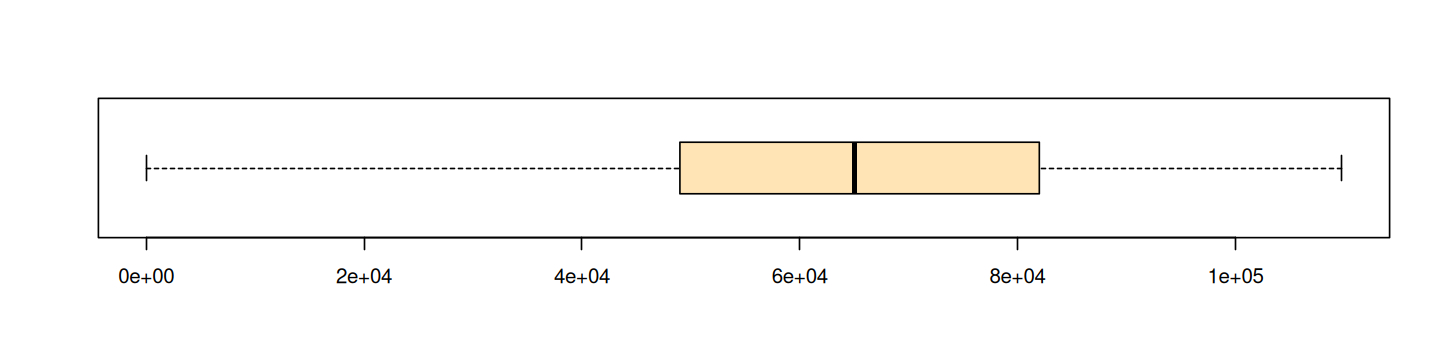

In [257]:
boxplot(sal$salario[sal$salario < 110000], horizontal=TRUE, col="moccasin")

Parece mais razoável. Talvez a exclusão dos valores mais altos, talvez em outras moedas, mostre uma distribuição mais próxima da correta. A real distribuição só será conhecida ao converter as diferentes moedas para uma única, provavelmente a `USD`.

#### `moeda`

In [258]:
head(sal$moeda)
tail(sal$moeda)

[1] "USD" "GBP" "USD" "USD" "USD" "USD"

[1] "USD" "USD" "USD" "USD" "USD" "USD"

In [259]:
unique(sal$moeda)

[1] "USD"     "GBP"     "CAD"     "EUR"     "AUD/NZD" "Other"   "CHF"    
 [8] "ZAR"     "SEK"     "HKD"     "JPY"

In [260]:
sal$moeda <- factor(sal$moeda)
print(summary(sal$moeda))

AUD/NZD     CAD     CHF     EUR     GBP     HKD     JPY   Other     SEK     USD 
    504    1673      37     643    1591       4      23     160      37   23387 
    ZAR 
     16 


#### `moeda_outra`

In [261]:
print(head(sal$moeda_outra,10))
print(tail(sal$moeda_outra,10))

 [1] "" "" "" "" "" "" "" "" "" ""
 [1] "" "" "" "" "" "" "" "" "" ""


In [262]:
mo <- sal$moeda_outra

Verificando quantas observações não tem valor para esta variável:

In [263]:
mo[nchar(mo) == 0] <- NA
(total_na <- sum(is.na(nchar(mo) == 0)))
(total <- length(mo))
(total_na/total)

[1] 27862

[1] 28075

[1] 0.9924132

Menos que 1% tem valores para esta variável.

As informações adicionais sobre a moeda são muito poucas e confusas. Há pouca chance de agregarem algo à análise.

In [264]:
sal$moeda_outra <- NULL

#### `pais`

In [265]:
head(sal$pais,20)
tail(sal$pais,20)

[1] "United States"   "United Kingdom"  "US"              "USA"            
 [5] "US"              "USA"             "USA"             "United States"  
 [9] "US"              "United States"   "United States"   "USA"            
[13] "United States"   "United States"   "Canada"          "United Kingdom "
[17] "USA"             "usa"             "USA"             "United States"

[1] "Canada"                   "Canada"                  
 [3] "United States "           "USA"                     
 [5] "Myanmar"                  "Burma"                   
 [7] "Nigeria "                 "United States"           
 [9] "USA"                      "USA"                     
[11] "USA"                      "United States "          
[13] "United States of America" "U.S."                    
[15] "USA"                      "United States"           
[17] "USA"                      "China"                   
[19] "United States"            "United States"

In [266]:
library(stringr)
p  <- str_to_title(trimws(sal$pais))

In [267]:
head(unique(p), 30)

[1] "United States"            "United Kingdom"          
 [3] "Us"                       "Usa"                     
 [5] "Canada"                   "Uk"                      
 [7] "Scotland"                 "U.s."                    
 [9] "The Netherlands"          "Australia"               
[11] "Spain"                    "England"                 
[13] "Finland"                  "United States Of America"
[15] "France"                   "Germany"                 
[17] "Ireland"                  "India"                   
[19] "U.s>"                     "Isa"                     
[21] "Argentina"                "Great Britain"           
[23] "United State"             "U.s.a"                   
[25] "Denmark"                  "U.s.a."                  
[27] "America"                  "Netherlands"             
[29] "Switzerland"              "Bermuda"

In [268]:
p[(grepl("u.( )?s(.)?", p, ignore.case=TRUE))]  <- 'U.S.A.'

In [269]:
p[grepl("states", p, ignore.case = TRUE)]  <- 'U.S.A.'
p[grepl(".nite. sta.e.", p, ignore.case=TRUE)] <- 'U.S.A.'
p[grepl("usa", p, ignore.case=TRUE)] <- 'U.S.A.'
p[grepl("us", p, ignore.case=TRUE)] <- 'U.S.A.'
p[grepl("america", p, ignore.case=TRUE)] <- 'U.S.A.'
p[substring(p,1,8) == "United S"] <- 'U.S.A.'
p[grepl("unitedstates", p, ignore.case=TRUE)] <- 'U.S.A.'
p[grepl("un(i)?(i)?(t|y)(i)?(e|i)(d)? stat(t)?.s",p,ignore.case = TRUE)] <- 'U.S.A.'
p[p == '🇺🇸'] <- 'U.S.A.'
p[p == 'ISA'] <- 'U.S.A.'
p[grepl("un(i)?(i)?(t|y)(t)?(e)?(e|i)(d|s)? s(t)?(a)?t.s",p,ignore.case = TRUE)] <- 'U.S.A.'

In [270]:
p[grepl("united kingdom", p, ignore.case=TRUE)] <- "U.K."
p[grepl("uk$", p, ignore.case=TRUE)] <- 'U.K.'
p[grepl("u.k$", p, ignore.case=TRUE)] <- 'U.K.'
p[grepl("u.k.$", p, ignore.case=TRUE)] <- 'U.K.'
p[grepl("u.k.,", p, ignore.case=TRUE)] <- 'U.K.'
p[grepl("uk ", p, ignore.case=TRUE)] <- 'U.K.'
p[grepl("uk,", p, ignore.case=TRUE)] <- 'U.K.'
p[grepl("unite...in(g)?do*", p, ignore.case=TRUE)] <- "U.K."
p[grepl("great brit.", p, ignore.case = TRUE)] <- "U.K."
p[grepl("englan.", p, ignore.case = TRUE)] <- "U.K."
p[grepl("wales.", p, ignore.case = TRUE)] <- "U.K."
p[grepl("wales", p, ignore.case = TRUE)] <- "U.K."
p[grepl("Scotlan.", p, ignore.case = TRUE)] <- "U.K."
p[grepl("britai.", p, ignore.case = TRUE)] <- "U.K."
p[grepl("london", p, ignore.case = TRUE)] <- "U.K."

In [271]:
p[grepl("Can.", p, ignore.case = TRUE)] <- 'Canada'
p[p == "Can"] <- 'Canada'
p[p == "Csnada"] <- 'Canada'

In [272]:
p[grepl("spain", p, ignore.case = TRUE)] <- 'Spain'
p[grepl("brasil", p, ignore.case = TRUE)] <- 'Brazil'
p[grepl("d(a|e)nmark", p, ignore.case=TRUE)] <- 'Denmark'
p[grepl("netherland", p, ignore.case=TRUE)] <- 'The Netherlands'
p[p == "NL"] <- 'The Netherlands'
p[grepl("new zealan.", p, ignore.case = TRUE)] <- "New Zealand"
p[p == "NZ"] <- "New Zealand"
p[grepl("i.dia", p, ignore.case = TRUE)] <- "India"
p[grepl("n(i)?geria", p, ignore.case = TRUE)] <- "Nigeria"
p[grepl("hong kon.", p, ignore.case = TRUE)] <- "Hong Kong"
p[grepl("czechia", p, ignore.case = TRUE)] <- "Czech Republic"
p[substring(p, 1, 5) == 'Italy'] <- 'Italy'

In [273]:
unique(p)

[1] "U.S.A."                                                                                                                                                                                     
  [2] "U.K."                                                                                                                                                                                       
  [3] "Canada"                                                                                                                                                                                     
  [4] "The Netherlands"                                                                                                                                                                            
  [5] "Spain"                                                                                                                                                                                      
  [6] "Finland"                                                                                                                                                                                    
  [7] "France"                                                                                                                                                                                     
  [8] "Germany"                                                                                                                                                                                    
  [9] "Ireland"                                                                                                                                                                                    
 [10] "India"                                                                                                                                                                                      
 [11] "Isa"                                                                                                                                                                                        
 [12] "Argentina"                                                                                                                                                                                  
 [13] "Denmark"                                                                                                                                                                                    
 [14] "Switzerland"                                                                                                                                                                                
 [15] "Bermuda"                                                                                                                                                                                    
 [16] "Malaysia"                                                                                                                                                                                   
 [17] "Mexico"                                                                                                                                                                                     
 [18] "South Africa"                                                                                                                                                                               
 [19] "Belgium"                                                                                                                                                                                    
 [20] "Northern Ireland"                                                                                                                                                                           
 [21] "Sweden"                                                                    

In [274]:
pfat <- factor(p)
summary(pfat)

U.S.A. 
                                                                                                                                                                                      23606 
                                                                                                                                                                                     Canada 
                                                                                                                                                                                       1686 
                                                                                                                                                                                       U.K. 
                                                                                                                                                                                       1593 
                                                                                                                                                                                    Germany 
                                                                                                                                                                                        195 
                                                                                                                                                                                New Zealand 
                                                                                                                                                                                        126 
                                                                                                                                                                                    Ireland 
                                                                                                                                                                                        124 
                                                                                                                                                                            The Netherlands 
                                                                                                                                                                                         88 
                                                                                                                                                                                     France 
                                                                                                                                                                                         68 
                                                                                                                                                                                      Spain 
                                                                                                                                                                                         49 
                                                                                                                                                                                     Sweden 
                                                                                                                                                                                         41 
                                                                                                                                                                                Switzerland 
                                                                                                                                                                                         38 
                       

In [275]:
total <- nrow(sal)
topo  <- 23606+1686+1592+195+126+124+88+68+49+41+38+35+29+24+22+19+16+15+14+13+12+10+10
topo / total * 100

[1] 99.13446

Compondo até a categoria ter 99% com países conhecidos, temos:

In [276]:
p[ p != 'U.S.A.' &   p != 'Canada' &   p != 'U.K.' &   p != 'Germany' &
   p != 'New Zealand' &   p != 'Ireland' &   p != 'France' &
   p != 'Netherlands' &   p != 'Spain' &   p != 'Sweden' &  p != 'Switzerland' &
   p != 'Belgium' &  p != 'Japan' &  p != 'Denmark' &  p != 'India' &  
   p != 'Singapore' &  p != 'South Africa' &  p != 'Finland' &  p != 'Italy' & 
   p != 'Israel' &  p != 'Norway' &  p != 'Malaysia' &  p != 'Brazil' &  
   p != 'Philippines' &  p != 'Poland' ] <- 'other' 
p <- factor(p)

In [277]:
sal$pais <- p

In [278]:
summary(sal)

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
    salario              bonus               moeda       salario_contexto  
 Min.   :        0   Min.   

#### `estado_eua`

In [279]:
head(sal$estado_eua)
tail(sal$estado_eua)

[1] "Massachusetts"  ""               "Tennessee"      "Wisconsin"     
[5] "South Carolina" "New Hampshire"

[1] "Nevada"  "Georgia" "Georgia" ""        "Georgia" "Georgia"

In [280]:
unique(sal$estado_eua)

[1] "Massachusetts"                                                                                                     
  [2] ""                                                                                                                  
  [3] "Tennessee"                                                                                                         
  [4] "Wisconsin"                                                                                                         
  [5] "South Carolina"                                                                                                    
  [6] "New Hampshire"                                                                                                     
  [7] "Arizona"                                                                                                           
  [8] "Missouri"                                                                                                          
  [9] "Florida"                                                                                                           
 [10] "Pennsylvania"                                                                                                      
 [11] "Michigan"                                                                                                          
 [12] "Minnesota"                                                                                                         
 [13] "Illinois"                                                                                                          
 [14] "California"                                                                                                        
 [15] "Georgia"                                                                                                           
 [16] "Ohio"                                                                                                              
 [17] "District of Columbia"                                                                                              
 [18] "Maryland"                                                                                                          
 [19] "Texas"                                                                                                             
 [20] "Virginia"                                                                                                          
 [21] "North Carolina"                                                                                                    
 [22] "New York"                                                                                                          
 [23] "New Jersey"                                                                                                        
 [24] "Rhode Island"                                                                                                      
 [25] "Colorado"                                                                                                          
 [26] "Oregon"                                                                                                            
 [27] "Washington"                                                                                                        
 [28] "Indiana"                                                                                                           
 [29] "Iowa"                                                                                                              
 [30] "Nebraska"                                                                                                          
 [31] "Oklahoma"                                                                                                          
 [32] "Maine"                                                                                                             
 [33] "Connecticut"                                               

Aparentemente como o estado também devia ser uma escolha múltipla, há respondentes com múltiplos estados; alguns casos com mais que 10 estados. Descartando.

In [281]:
sal$estado_eua <- NULL

#### `cidade`

In [282]:
head(sal$cidade)
tail(sal$cidade)

[1] "Boston"      "Cambridge"   "Chattanooga" "Milwaukee"   "Greenville" 
[6] "Hanover"

[1] "Las Vegas"     "Milledgeville" "Johns Creek"   "Shenzhen"     
[5] "Tucker"        "Roswell"

In [283]:
unique(sal$cidade)

[1] "Boston"                                                                                                                                                                     
   [2] "Cambridge"                                                                                                                                                                  
   [3] "Chattanooga"                                                                                                                                                                
   [4] "Milwaukee"                                                                                                                                                                  
   [5] "Greenville"                                                                                                                                                                 
   [6] "Hanover"                                                                                                                                                                    
   [7] "Columbia"                                                                                                                                                                   
   [8] "Yuma"                                                                                                                                                                       
   [9] "St. Louis"                                                                                                                                                                  
  [10] "Palm Coast"                                                                                                                                                                 
  [11] "Boston, MA"                                                                                                                                                                 
  [12] "Scranton"                                                                                                                                                                   
  [13] "Detroit"                                                                                                                                                                    
  [14] "Saint Paul"                                                                                                                                                                 
  [15] "Remote"                                                                                                                                                                     
  [16] "Lincoln"                                                                                                                                                                    
  [17] "Chicago"                                                                                                                                                                    
  [18] "Pomona"                                                                                                                                                                     
  [19] "Atlanta"                                                                                                                                                                    
  [20] "Boca Raton"                                                                                                                                                                 
  [21] "Philadelphia"                                                                                                                                                               
  [22] "Toronto"                                                                                                                                                                    
  [23] "Dayton"      

Seria interessante manter como curiosidade, porém é de pouca utilidade em uma análise.

In [284]:
sal$cidade <- NULL

#### `anos_exp_total`

In [285]:
unique(sal$anos_exp_total)

[1] "5-7 years"        "8 - 10 years"     "2 - 4 years"      "21 - 30 years"   
[5] "11 - 20 years"    "1 year or less"   "41 years or more" "31 - 40 years"

In [286]:
aet <- sal$anos_exp_total
aet[aet == '1 year or less'   ] <-    "-1"
aet[aet == '2 - 4 years'      ] <-   "2-4"
aet[aet == '5-7 years'        ] <-   "5-7"
aet[aet == '8 - 10 years'     ] <-  "8-10"
aet[aet == '11 - 20 years'    ] <- "11-20"
aet[aet == '21 - 30 years'    ] <- "21-30"
aet[aet == '31 - 40 years'    ] <- "31-40"
aet[aet == '41 years or more' ] <-   "41+"
ordem <- c("-1", "2-4", "5-7", "8-10", "11-20", 
           "21-30", "31-40", "41+")
aet <- factor(aet, ordered = TRUE, levels = ordem)

In [287]:
print(summary(aet))

   -1   2-4   5-7  8-10 11-20 21-30 31-40   41+ 
  527  3030  4883  5379  9625  3637   870   124 


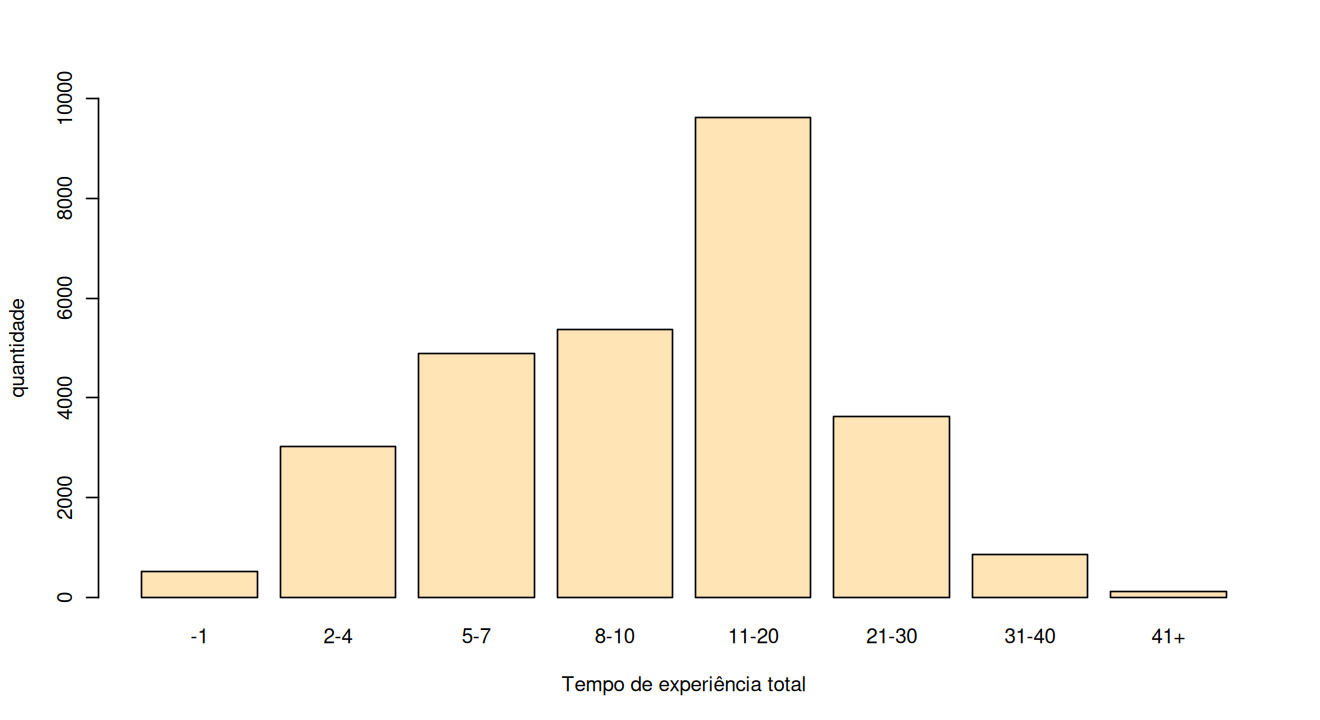

In [288]:
dimgraf(11,6)
barplot(table(aet),ylim=c(0,10000), col="moccasin", 
        xlab="Tempo de experiência total", ylab="quantidade")

In [289]:
sal$anos_exp_total <- aet

In [290]:
summary(sal)

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
    salario              bonus               moeda       salario_contexto  
 Min.   :        0   Min.   

#### `anos_exp_area`

In [291]:
unique(sal$anos_exp_area)

[1] "5-7 years"        "2 - 4 years"      "21 - 30 years"    "11 - 20 years"   
[5] "1 year or less"   "8 - 10 years"     "31 - 40 years"    "41 years or more"

In [292]:
ae <- sal$anos_exp_area
ae[ae == '1 year or less'   ] <-    "-1"
ae[ae == '2 - 4 years'      ] <-   "2-4"
ae[ae == '5-7 years'        ] <-   "5-7"
ae[ae == '8 - 10 years'     ] <-  "8-10"
ae[ae == '11 - 20 years'    ] <- "11-20"
ae[ae == '21 - 30 years'    ] <- "21-30"
ae[ae == '31 - 40 years'    ] <- "31-40"
ae[ae == '41 years or more' ] <-   "41+"
ordem <- c("-1", "2-4", "5-7", "8-10", "11-20", 
           "21-30", "31-40", "41+")
ae <- factor(ae, ordered = TRUE, levels = ordem)

In [293]:
print(summary(aet))

   -1   2-4   5-7  8-10 11-20 21-30 31-40   41+ 
  527  3030  4883  5379  9625  3637   870   124 


In [294]:
print(summary(ae))

   -1   2-4   5-7  8-10 11-20 21-30 31-40   41+ 
 1492  6252  6520  4982  6537  1868   383    41 


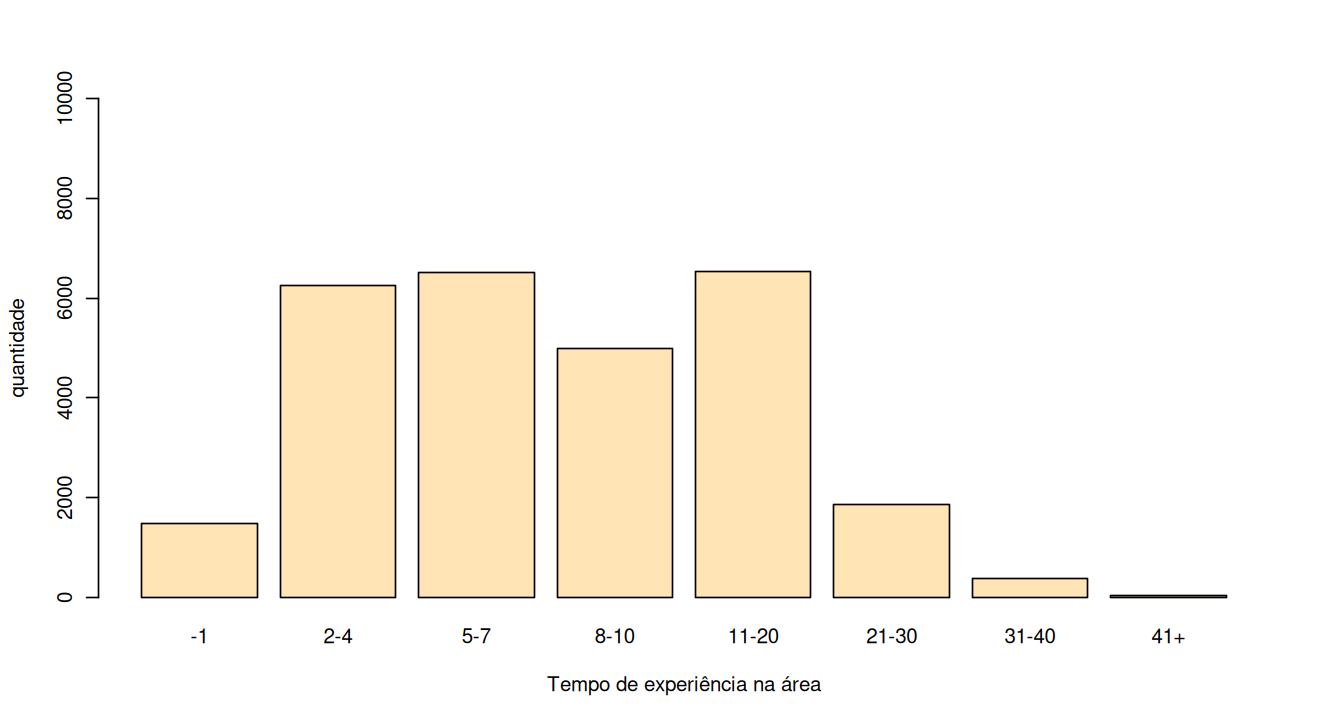

In [295]:
dimgraf(11,6)
barplot(table(ae),ylim=c(0,10000), col="moccasin", 
        xlab="Tempo de experiência na área", ylab="quantidade")

In [296]:
sal$anos_exp_area <- ae

In [297]:
summary(sal)

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
    salario              bonus               moeda       salario_contexto  
 Min.   :        0   Min.   

#### `educacao`

In [298]:
ed <- sal$educacao

In [299]:
head(ed)
tail(ed)

[1] "Master's degree" "College degree"  "College degree"  "College degree" 
[5] "College degree"  "Master's degree"

[1] "Master's degree" "Master's degree" "Master's degree" "Master's degree"
[5] "College degree"  "Some college"

In [300]:
unique(ed)
summary(factor(ed))

[1] "Master's degree"                    "College degree"                    
[3] "PhD"                                ""                                  
[5] "Some college"                       "High School"                       
[7] "Professional degree (MD, JD, etc.)"

College degree 
                               222                              13527 
                       High School                    Master's degree 
                               639                               8869 
                               PhD Professional degree (MD, JD, etc.) 
                              1426                               1324 
                      Some college 
                              2068

In [301]:
ed[ed == ""] <- "not informed"
ordem <- c("not informed","High School","Some college",
           "College degree","Master's degree",
           "Professional degree (MD, JD, etc.)", "PhD")
ed2 <- substring(ed, 1, 15)
ed  <- factor(ed,  ordered = TRUE, levels = ordem)
ed2 <- factor(ed2, ordered = TRUE, levels = substring(ordem,1,15))

In [302]:
print(summary(ed))

                      not informed                        High School 
                               222                                639 
                      Some college                     College degree 
                              2068                              13527 
                   Master's degree Professional degree (MD, JD, etc.) 
                              8869                               1324 
                               PhD 
                              1426 


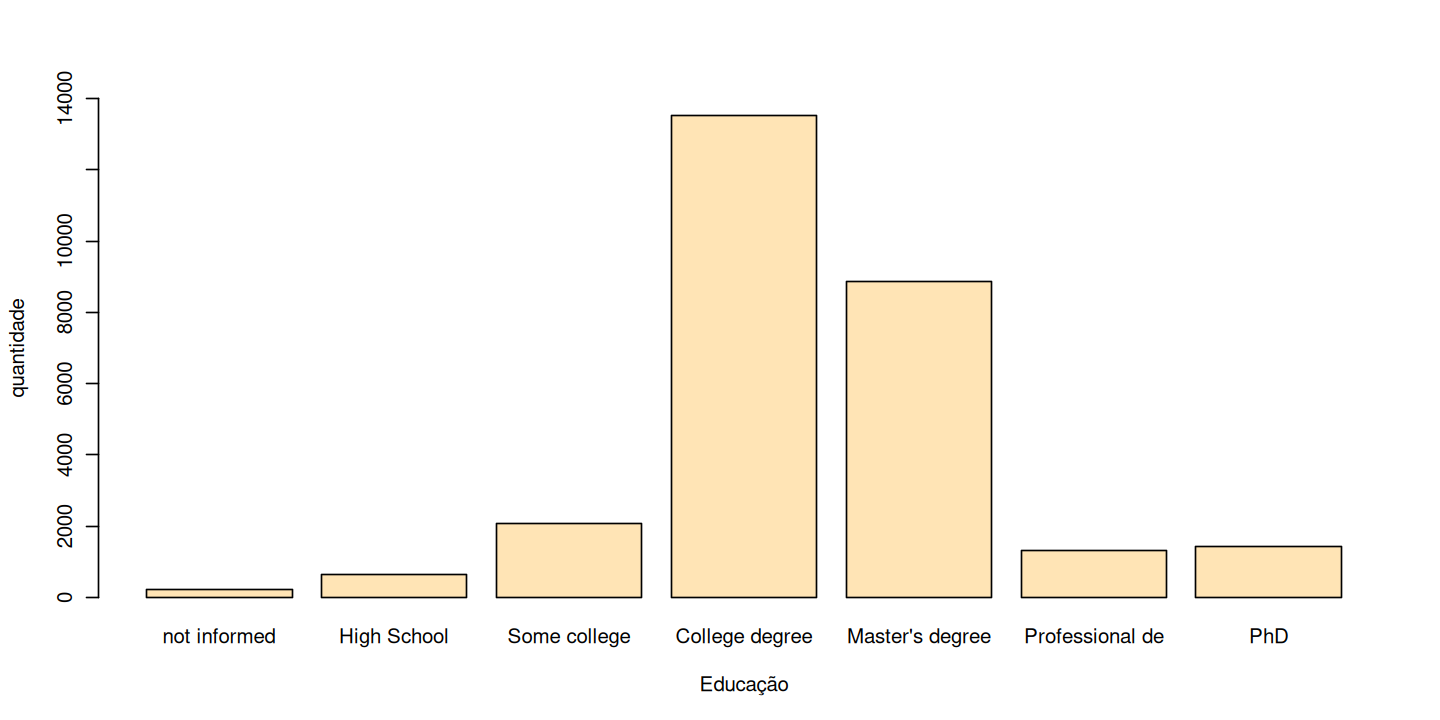

In [303]:
dimgraf(12,6)
barplot(table(ed2),ylim=c(0,14000), col="moccasin", 
        xlab="Educação", ylab="quantidade")

In [304]:
sal$educacao <- ed

In [305]:
summary(sal)

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
    salario              bonus               moeda       salario_contexto  
 Min.   :        0   Min.   

#### `sexo`

In [306]:
s <- sal$sexo

In [307]:
unique(s)

[1] "Woman"                         "Non-binary"                   
[3] "Man"                           ""                             
[5] "Other or prefer not to answer" "Prefer not to answer"

In [308]:
s[s == "Woman"] <- "feminino"

s[s == "Man"]   <- "masculino"

s[s == "Non-binary"]   <- "não binário"

s[s == "Other or prefer not to answer" |
  s == "Prefer not to answer" |
  s == ""]   <- "prefere não responder"
ordem <- c("feminino", "masculino", "não binário",
           "prefere não responder")
s <- factor(s, ordered = TRUE, levels = ordem)

In [309]:
print(summary(s))

             feminino             masculino           não binário 
                21372                  5488                   745 
prefere não responder 
                  470 


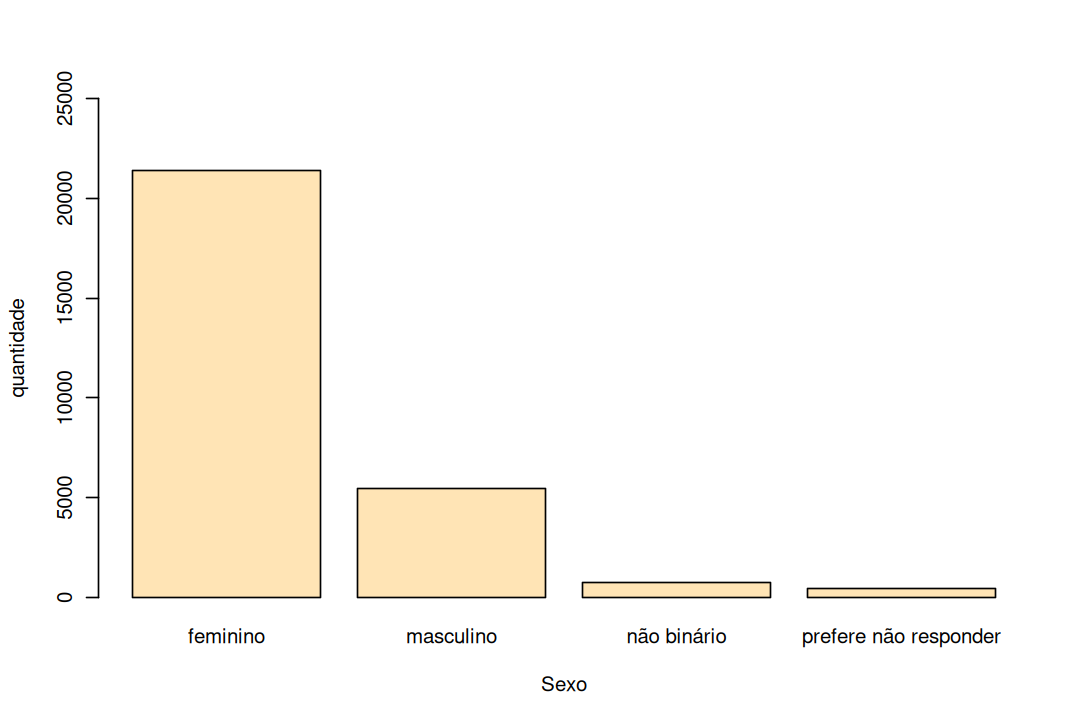

In [310]:
dimgraf(9,6)
barplot(table(s),ylim=c(0,25000), col="moccasin", 
        xlab="Sexo", ylab="quantidade")

In [311]:
sal$sexo <- s

In [312]:
summary(sal)

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
    salario              bonus               moeda       salario_contexto  
 Min.   :        0   Min.   

#### `etnia`

In [313]:
et <- sal$etnia

In [314]:
unique(et)

[1] "White"                                                                                                                                                                                                                       
 [2] "Hispanic, Latino, or Spanish origin, White"                                                                                                                                                                                  
 [3] "Asian or Asian American, White"                                                                                                                                                                                              
 [4] "Asian or Asian American"                                                                                                                                                                                                     
 [5] "Another option not listed here or prefer not to answer"                                                                                                                                                                      
 [6] "Hispanic, Latino, or Spanish origin"                                                                                                                                                                                         
 [7] "Middle Eastern or Northern African"                                                                                                                                                                                          
 [8] "Hispanic, Latino, or Spanish origin, Middle Eastern or Northern African, White"                                                                                                                                              
 [9] "Black or African American"                                                                                                                                                                                                   
[10] "Black or African American, White"                                                                                                                                                                                            
[11] ""                                                                                                                                                                                                                            
[12] "Black or African American, Hispanic, Latino, or Spanish origin, White"                                                                                                                                                       
[13] "Native American or Alaska Native"                                                                                                                                                                                            
[14] "Native American or Alaska Native, White"                                                                                                                                                                                     
[15] "Hispanic, Latino, or Spanish origin, Another option not listed here or prefer not to answer"                                                                                                                                 
[16] "Black or African American, Middle Eastern or Northern African, Native American or Alaska Native, White"                                                                                                                      
[17] "White, Another option not listed here or prefer not to answer"                                                                                                                                                               
[18] "Black or African American, Native American or Alaska Native, White"                                                    

In [315]:
summary(factor(et))

177 
                                                                                                                                                                      Another option not listed here or prefer not to answer 
                                                                                                                                                                                                                         623 
                                                                                                                                                                                                     Asian or Asian American 
                                                                                                                                                                                                                        1406 
                                                                                                                                             Asian or Asian American, Another option not listed here or prefer not to answer 
                                                                                                                                                                                                                          11 
                                                                                                                                                                          Asian or Asian American, Black or African American 
                                                                                                                                                                                                                           9 
                                                                                                                                     Asian or Asian American, Black or African American, Hispanic, Latino, or Spanish origin 
                                                                                                                                                                                                                           1 
Asian or Asian American, Black or African American, Hispanic, Latino, or Spanish origin, Middle Eastern or Northern African, Native American or Alaska Native, White, Another option not listed here or prefer not to answer 
                                                                                                                                                                                                                           1 
                                                                                                                                 Asian or Asian American, Black or African American, Native American or Alaska Native, White 
                                                                                                                                                                                                                           1 
                                                                                                                                                                   Asian or Asian American, Black or African American, White 
                                                                                                                                                                                                                           6 
                                                                                                                                                                Asian or Asian American, Hispanic, Latino, or Spanish origin 
                                                                                                                                                                                                                          14 

In [316]:
et[grepl("black", et, ignore.case = TRUE) & grepl("white", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("black", et, ignore.case = TRUE) & grepl("asian", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("black", et, ignore.case = TRUE) & grepl("northern", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("black", et, ignore.case = TRUE) & grepl("hispanic", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("black", et, ignore.case = TRUE) & grepl("native", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("asian", et, ignore.case = TRUE) & grepl("northern", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("asian", et, ignore.case = TRUE) & grepl("latino", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("asian", et, ignore.case = TRUE) & grepl("native", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("latino", et, ignore.case = TRUE) & grepl("northern", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("latino", et, ignore.case = TRUE) & grepl("native", et, ignore.case = TRUE)] <- 0 # "multiple"
et[grepl("northern", et, ignore.case = TRUE) & grepl("native", et, ignore.case = TRUE)] <- 0 # "multiple"

In [317]:
et[grepl("prefer not to answer",et,ignore.case = TRUE)] <- "1" # "prefer not to answer"
et[et == ""] <- '1' # "prefer not to answer"

In [318]:
et[et == 'Asian or Asian American'] <- '2' # Asian or Asian American
et[et == 'Asian or Asian American, White'] <- '2' 

In [319]:
et[et == 'Hispanic, Latino, or Spanish origin'] <- '3' #Hispanic, Latino, or Spanish origin
et[et == 'Hispanic, Latino, or Spanish origin, White'] <- '3'

In [320]:
et[et == 'Native American or Alaska Native'] <- '4' #Native American or Alaska Native
et[et == 'Native American or Alaska Native, White'] <- '4' #Native American or Alaska Native

In [321]:
et[et == 'Black or African American'] <- '5' #Black or African American

In [322]:
et[et == 'Middle Eastern or Northern African'] <- '6' #Middle Eastern or Northern African
et[et == 'Middle Eastern or Northern African, White'] <- '6' 

In [323]:
et[et == 'White'] <- 'Branco'
et[et == '0'] <- 'Múltiplo'
et[et == '1'] <- 'Não forneceu'
et[et == '2'] <- 'Asiático'
et[et == '3'] <- 'Latino/Hispânico'
et[et == '4'] <- 'Orig. América do Norte'
et[et == '5'] <- 'Afrodescendente'
et[et == '6'] <- 'Oriente médio'
ordem <- c('Afrodescendente', 'Asiático', 'Branco', 'Latino/Hispânico', 'Oriente médio', 
           'Orig. América do Norte', 'Múltiplo', 'Não forneceu')

In [324]:
et <- factor(et, ordered = TRUE, levels = ordem)

In [325]:
print(summary(et))

       Afrodescendente               Asiático                 Branco 
                   690                   1749                  23219 
      Latino/Hispânico          Oriente médio Orig. América do Norte 
                   988                    152                    110 
              Múltiplo           Não forneceu 
                   272                    895 


In [326]:
sal$etnia <- et

In [327]:
print(summary(sal))

     tempo                          idade      
 Min.   :2021-04-27 11:02:10.00   -18  :   14  
 1st Qu.:2021-04-27 14:21:35.50   18-24: 1224  
 Median :2021-04-28 13:57:11.00   25-34:12660  
 Mean   :2021-05-15 10:18:53.21   35-44: 9902  
 3rd Qu.:2021-04-29 20:31:53.50   45-54: 3189  
 Max.   :2024-09-17 12:03:31.00   55-64:  992  
                                  65+  :   94  
                                industria       cargo          
 other                               :5465   Length:28075      
 computing or tech                   :4704   Class :character  
 education (higher education)        :2466   Mode  :character  
 nonprofits                          :2419                     
 health care                         :1896                     
 government and public administration:1890                     
 (Other)                             :9235                     
    salario              bonus               moeda       salario_contexto  
 Min.   :        0   Min.   

In [328]:
save(sal, file="SalarySurvey2021_02_limpeza.RData")

In [329]:
rm(list=ls())
dimgraf <- function (x=11, y=7) { options(repr.plot.width=x,repr.plot.height=y) }
load("SalarySurvey2021_02_limpeza.RData")
ls()

[1] "dimgraf" "sal"

## Conformação do salário em USD

In [330]:
s <- sal$salario
nomes <- names(sal)
nomes[nomes == 'salario'] <- 'salario_antigo'
names(sal) <- nomes
m <- as.character(sal$moeda)

Pela taxa de câmbio de 28/09/24:

In [331]:
# (AUD = 0,69 + NZD = 0,63)/2 -> 0,66
s <- ifelse(m == 'AUD/NZD', s * 0.66, s) 
s <- ifelse(m == 'CAD', s *  0.74, s) 
s <- ifelse(m == 'CHF', s *  1.19, s) 
s <- ifelse(m == 'EUR', s *  1.12, s) 
s <- ifelse(m == 'GBP', s *  1.34, s) 
s <- ifelse(m == 'HKD', s *  0.13, s) 
s <- ifelse(m == 'JPY', s * 0.007, s) 
s <- ifelse(m == 'SEK', s *  0.13, s) 
s <- ifelse(m == 'ZAR', s *  0.06, s) 

In [332]:
s[m == 'Other'] <- NA

In [333]:
print(summary(factor(m)))

AUD/NZD     CAD     CHF     EUR     GBP     HKD     JPY   Other     SEK     USD 
    504    1673      37     643    1591       4      23     160      37   23387 
    ZAR 
     16 


In [334]:
summary(s)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max.      NA's 
        0     53280     74000     91970    106000 102000000       160 

In [335]:
sal$salario <- s

Quais são essses salários que parecem exagerados?

In [336]:
sal[!is.na(sal$salario) &
    (sal$salario > 200000) & 
    sal$moeda != 'USD' ,c('pais','salario_antigo', 
                          'salario_contexto','moeda', 'salario') ]

,pais,salario_antigo,salario_contexto,moeda,salario
,<fct>,<dbl>,<chr>,<fct>,<dbl>
266,Germany,260000,,EUR,291200
3010,Canada,600000,,CAD,444000
5582,U.K.,910000,"Bonus depends on a LOT. With covid, it took a hit to about 150, but in all other years it's been 250",GBP,1219400
8588,U.K.,160000,,GBP,214400
9929,U.K.,156000,I receive about 100k in equity per year as well as a performance bonus.,GBP,209040
11658,Norway,550000,,EUR,616000
11755,U.K.,260000,,GBP,348400
11792,U.K.,150000,,GBP,201000
12437,U.K.,185000,,GBP,247900


In [337]:
sal[!is.na(sal$salario) &
    (sal$salario < 1200) &                       # menos que 100 USD por mês
    sal$moeda != 'USD' ,c('pais','salario_antigo', 
                          'salario_contexto','moeda', 'salario') ]

,pais,salario_antigo,salario_contexto,moeda,salario
,<fct>,<dbl>,<chr>,<fct>,<dbl>
167,Finland,35,,EUR,39.20
2230,Germany,33,"Before tax, insurance etc.",EUR,36.96
4547,Germany,63,,EUR,70.56
5140,Canada,118,,CAD,87.32
5880,other,18,,EUR,20.16
6295,U.K.,50,,GBP,67.00
6930,Canada,52,,CAD,38.48
8593,Germany,100,,EUR,112.00
8680,Canada,91,,CAD,67.34


Claramente salários anuais menores que 10 USD é um erro. Eliminando:

In [338]:
sal <- sal[sal$salario > 10,]

Para os demais casos, parece que o respondente considerou o salário * 1000, ou seja, quando encontramos 70, provavelmente seria 70k (70000). Porém, como é apenas especulação, esses valores também serão excluídos por estarem incorretos frente aos demais:

In [339]:
summary(sal$salario)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max.      NA's 
       15     53280     74400     92043    106000 102000000       160 

In [340]:
sal <- sal[sal$salario >= 1200,]

In [341]:
summary(sal$salario)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max.      NA's 
     1200     53600     75000     92344    106000 102000000       160 

In [342]:
save(sal, file="SalarySurvey2021_03_completo.RData")

## Separando observações próprias para análise

In [358]:
rm(list=ls())
dimgraf <- function (x=11, y=7) { options(repr.plot.width=x,repr.plot.height=y) }
load("SalarySurvey2021_03_completo.RData")
ls()

[1] "dimgraf" "sal"

In [359]:
str(sal)

'data.frame':	27962 obs. of  15 variables:
 $ tempo           : POSIXct, format: "2021-04-27 11:02:10" "2021-04-27 11:02:22" ...
 $ idade           : Ord.factor w/ 7 levels "-18"<"18-24"<..: 3 3 3 3 3 3 3 3 5 4 ...
 $ industria       : Factor w/ 15 levels "accounting, banking & finance",..: 4 3 1 13 1 4 14 5 3 1 ...
 $ cargo           : chr  "Research and Instruction Librarian" "Change & Internal Communications Manager" "Marketing Specialist" "Program Manager" ...
 $ salario_antigo  : num  55000 54600 34000 62000 60000 62000 33000 50000 112000 45000 ...
 $ bonus           : int  0 4000 NA 3000 7000 NA 2000 NA 10000 0 ...
 $ moeda           : Factor w/ 11 levels "AUD/NZD","CAD",..: 10 5 10 10 10 10 10 10 10 10 ...
 $ salario_contexto: chr  "" "" "" "" ...
 $ pais            : Factor w/ 25 levels "Belgium","Brazil",..: 25 24 25 25 25 25 25 25 25 25 ...
 $ anos_exp_total  : Ord.factor w/ 8 levels "-1"<"2-4"<"5-7"<..: 3 4 2 4 4 4 2 3 6 6 ...
 $ anos_exp_area   : Ord.factor w/ 8 levels "-1"

Uma vez que o salário está padronizado em USD, moeda, contexto, bônus, salário antigo podem ser excluídos pois não são atributos interessantes para a análise.

In [360]:
sal$moeda <- NULL
sal$salario_contexto <- NULL
sal$salario_antigo <- NULL
sal$bonus <- NULL

O marco temporal não é particularmente útil, pois o salário não é suposto flutuar por minutos ou dias. Assim, talvez obter apenas o ano e o mês.

In [361]:
sal$ano <- as.factor(as.integer(format(sal$tempo, "%Y")))
sal$mes <- as.factor(as.integer(format(sal$tempo, "%m")))

In [362]:
print(summary(sal$ano))
print(summary(sal$mes))
sal$tempo <- NULL

 2021  2022  2023  2024  NA's 
27362   307    73    60   160 
    1     2     3     4     5     6     7     8     9    10    11    12  NA's 
   58    67    53 22655  3619   152   100   162    76   697    96    67   160 


As observações sem salário (`NA`) podem ser interessantes para avaliar um modelo, mas não para treinar ou analisar o comportamento do salário. Será salvo então um conjunto de dados com os `NA`s e depois serão descartados.

In [363]:
summary(sal)

     idade                              industria        cargo          
 25-34  :12536   other                       : 5410   Length:27962      
 35-44  : 9833   computing or tech           : 4634   Class :character  
 45-54  : 3153   education (higher education): 2450   Mode  :character  
 18-24  : 1197   nonprofits                  : 2407                     
 55-64  :  977   health care                 : 1881                     
 (Other):  106   (Other)                     :11020                     
 NA's   :  160   NA's                        :  160                     
      pais       anos_exp_total anos_exp_area 
 U.S.A. :23516   11-20  :9554   11-20  :6489  
 Canada : 1679   8-10   :5341   5-7    :6470  
 U.K.   : 1586   5-7    :4844   2-4    :6174  
 other  :  245   21-30  :3601   8-10   :4939  
 Germany:  186   2-4    :2971   21-30  :1848  
 (Other):  590   (Other):1491   (Other):1882  
 NA's   :  160   NA's   : 160   NA's   : 160  
                               educacao 

In [364]:
sal <- sal[!is.na(sal$salario),]

In [365]:
summary(sal)

   idade                                      industria       cargo          
 -18  :   12   other                               :5410   Length:27802      
 18-24: 1197   computing or tech                   :4634   Class :character  
 25-34:12536   education (higher education)        :2450   Mode  :character  
 35-44: 9833   nonprofits                          :2407                     
 45-54: 3153   health care                         :1881                     
 55-64:  977   government and public administration:1877                     
 65+  :   94   (Other)                             :9143                     
          pais       anos_exp_total anos_exp_area 
 U.S.A.     :23516   11-20  :9554   11-20  :6489  
 Canada     : 1679   8-10   :5341   5-7    :6470  
 U.K.       : 1586   5-7    :4844   2-4    :6174  
 other      :  245   21-30  :3601   8-10   :4939  
 Germany    :  186   2-4    :2971   21-30  :1848  
 New Zealand:  124   31-40  : 858   -1     :1464  
 (Other)    :  466 

In [366]:
save(sal, file="SalarySurvey2021_04_sem_NA.RData")